In [1]:
! pip install autokeras

  Using cached autokeras-2.0.0-py3-none-any.whl (122 kB)
  Using cached keras_tuner-1.4.7-py3-none-any.whl (129 kB)
  Using cached dm_tree-0.1.8-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (152 kB)
  Using cached packaging-24.2-py3-none-any.whl (65 kB)
  Using cached autokeras-1.1.0-py3-none-any.whl (148 kB)
  Using cached keras_nlp-0.6.1-py3-none-any.whl (573 kB)
  Using cached tensorflow-2.13.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (479.6 MB)
  Using cached pandas-2.0.3-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.4 MB)
  Using cached rich-13.9.4-py3-none-any.whl (242 kB)
  Using cached keras_core-0.1.5-py3-none-any.whl (924 kB)
  Using cached absl_py-2.1.0-py3-none-any.whl (133 kB)
  Using cached tensorflow_text-2.13.0-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (6.5 MB)
  Using cached numpy-1.24.4-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.3 MB)
  Using cached regex-2024.11.6-cp38-cp38-manylinux_2_17_x86

In [2]:
import numpy as np
import tensorflow as tf
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.python.keras.utils.data_utils import Sequence
import autokeras as ak

2024-11-17 01:30:55.626090: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2024-11-17 01:30:56.638834: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2024-11-17 01:30:56.642625: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-11-17 01:30:57.962957: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
Using TensorFlow backend


In [3]:
physical_device = tf.config.experimental.list_physical_devices('GPU') or [None]
print("GPUs Available: ", len(tf.config.experimental.list_physical_devices('GPU')))

tf.config.experimental.set_memory_growth(physical_device[0], True) if physical_device[0] else None

GPUs Available:  0


In [4]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print(x_train.shape) 
print(y_train.shape) 
print(y_train[:3])

(60000, 28, 28)
(60000,)
[5 0 4]


In [5]:
y_train[:5]


array([5, 0, 4, 1, 9], dtype=uint8)

In [6]:
clf = ak.ImageClassifier(
    overwrite=True,
    max_trials=1)
history = clf.fit(x_train, y_train, epochs=8)

Trial 1 Complete [00h 18m 35s]
val_loss: 0.038249339908361435

Best val_loss So Far: 0.038249339908361435
Total elapsed time: 00h 18m 35s
Epoch 1/8
1875/1875 [==============================] - 163s 87ms/step - loss: 0.1601 - accuracy: 0.9513
Epoch 2/8
1875/1875 [==============================] - 162s 87ms/step - loss: 0.0745 - accuracy: 0.9768
Epoch 3/8
1875/1875 [==============================] - 163s 87ms/step - loss: 0.0585 - accuracy: 0.9820
Epoch 4/8
1875/1875 [==============================] - 162s 87ms/step - loss: 0.0511 - accuracy: 0.9840
Epoch 5/8
1875/1875 [==============================] - 164s 87ms/step - loss: 0.0454 - accuracy: 0.9851
Epoch 6/8
1875/1875 [==============================] - 163s 87ms/step - loss: 0.0401 - accuracy: 0.9875
Epoch 7/8
1875/1875 [==============================] - 162s 86ms/step - loss: 0.0377 - accuracy: 0.9877
Epoch 8/8
1875/1875 [==============================] - 163s 87ms/step - loss: 0.0333 - accuracy: 0.9892
INFO:tensorflow:Assets written

In [7]:
model = clf.export_model()

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28)]          0         
                                                                 
 cast_to_float32 (CastToFlo  (None, 28, 28)            0         
 at32)                                                           
                                                                 
 expand_last_dim (ExpandLas  (None, 28, 28, 1)         0         
 tDim)                                                           
                                                                 
 normalization (Normalizati  (None, 28, 28, 1)         3         
 on)                                                             
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                             

In [8]:
import matplotlib.pyplot as plt
def plotImages(images_arr):
    fig, axes = plt.subplots(1, 10, figsize=(20,20))
    axes = axes.flatten()
    for img, ax in zip( images_arr, axes):
        ax.imshow(img)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

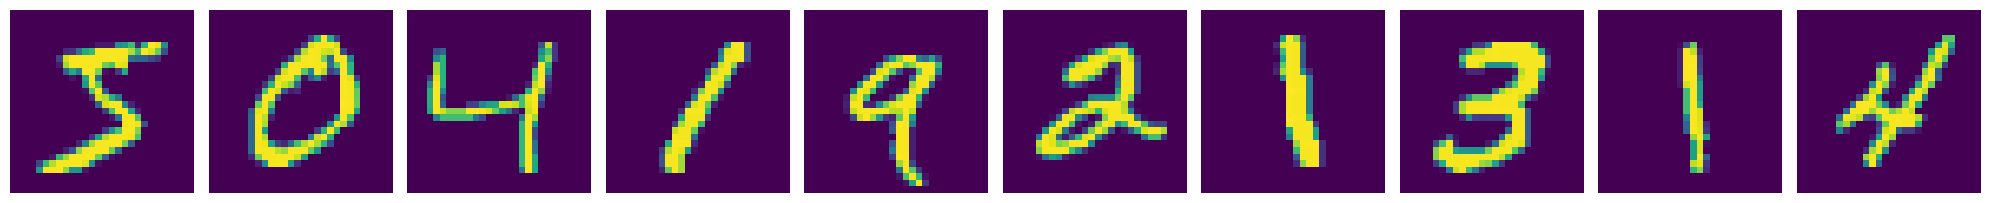

In [9]:
plotImages(x_train[:10])

In [10]:
predicted_y = clf.predict(x_test[:6])
print(predicted_y)

1/1 [==============================] - 0s 5ms/step
[['7']
 ['2']
 ['1']
 ['0']
 ['4']
 ['1']]


In [11]:
print(clf.evaluate(x_test, y_test))

313/313 [==============================] - 6s 20ms/step - loss: 0.0315 - accuracy: 0.9898
[0.03150485083460808, 0.989799976348877]


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=d7cfd244-2284-41c3-a075-b2ac675dbceb' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>